In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

pd.set_option("display.max_columns", None, "display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
from src import config as C

# 02 — Veriyi Anlama (Data Understanding)

**Kural: Bu notebook'ta veriyi DEĞİŞTİRMİYORUZ.** Sadece bakıyor, soruyor ve sorunları listeliyoruz.
Ham veri `data/raw/` altında dokunulmaz kalır; temizleme Notebook 03'te yeni bir kopya üzerinde yapılır.

## 2.1 Veriyi okuma
`monthly_fee_tl` sütununu `dtype="object"` (metin) olarak okuyoruz. **Neden?** Pandas bu sütunda `399TL`, `free` gibi değerler görürse zaten metin yapar; bilinçli olarak metin okuyarak bu bozuk değerleri *görebiliriz*.

In [2]:
df_raw = pd.read_csv(C.RAW_PATH, dtype={"monthly_fee_tl": "object"})
display(df_raw.head())
print("Satır, sütun:", df_raw.shape)

,customer_id,age,region,device_type,plan,contract_type,tenure_months,monthly_usage_hours,monthly_fee_tl,discount_rate,payment_method,late_payments_6m,support_calls_6m,complaints_6m,satisfaction_score,churn
0,CUST100000,105.000,Central Anatolia,Desktop,Standard,Monthly,26,33.000,399.0,0.000,Credit Card,1,2,0,5.500,0
1,CUST100001,70.000,Mediterranean,Mobile,Standard,Annual,61,88.300,359.1,0.100,Bank Transfer,0,0,0,7.400,0
2,CUST100002,27.000,Aegean,Mobile,Premium,Monthly,61,50.000,599.0,0.000,Credit Card,0,2,0,5.400,0
3,CUST100003,32.000,Black Sea,Desktop,Premium,Monthly,22,58.000,599.0,0.000,Credit Card,1,0,0,6.000,1
4,CUST100004,47.000,Mediterranean,Mobile,Basic,Annual,41,70.100,224.1,0.100,Cash,1,0,0,7.900,0


Satır, sütun: (1820, 16)


## 2.2 Veri tipleri ve eksiklik özeti — `info()`

In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1820 entries, 0 to 1819
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer_id          1820 non-null   str    
 1   age                  1773 non-null   float64
 2   region               1788 non-null   str    
 3   device_type          1820 non-null   str    
 4   plan                 1820 non-null   str    
 5   contract_type        1820 non-null   str    
 6   tenure_months        1820 non-null   int64  
 7   monthly_usage_hours  1757 non-null   float64
 8   monthly_fee_tl       1797 non-null   object 
 9   discount_rate        1820 non-null   float64
 10  payment_method       1793 non-null   str    
 11  late_payments_6m     1820 non-null   int64  
 12  support_calls_6m     1820 non-null   int64  
 13  complaints_6m        1820 non-null   int64  
 14  satisfaction_score   1739 non-null   float64
 15  churn                1820 non-null   int64  
dtyp

**Okuma:** `monthly_fee_tl` metin (object) — sayısal olmalıydı. `age`, `region`, `monthly_usage_hours`, `payment_method`, `satisfaction_score` sütunlarında boş değerler var.

## 2.3 Sayısal özet — `describe()`

In [4]:
display(df_raw.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,"1,773.000",46.671,17.130,-3.000,32.000,47.000,61.000,130.000
tenure_months,"1,820.000",37.103,20.567,1.000,19.000,38.000,55.000,72.000
monthly_usage_hours,"1,757.000",42.513,16.182,-5.000,31.600,42.100,53.100,180.000
discount_rate,"1,820.000",0.074,0.067,0.000,0.000,0.100,0.100,0.200
late_payments_6m,"1,820.000",0.546,0.746,0.000,0.000,0.000,1.000,4.000
support_calls_6m,"1,820.000",1.283,1.157,0.000,0.000,1.000,2.000,6.000
complaints_6m,"1,820.000",0.425,0.667,0.000,0.000,0.000,1.000,4.000
satisfaction_score,"1,739.000",6.150,1.763,0.000,5.000,6.200,7.400,11.000
churn,"1,820.000",0.083,0.276,0.000,0.000,0.000,0.000,1.000


**Okuma (kırmızı bayraklar):**
* `age`: min **-3**, max **130** → imkânsız yaşlar.
* `monthly_usage_hours`: min **-5**, max **180** → negatif değerler imkânsız, 100 saat üstü de şüpheli (veri sözlüğüne göre makul aralık 0–100).
* `satisfaction_score`: min **0**, max **11** → ölçek 1–10 olmalı.
* Diğerleri (tenure, discount, sayaçlar) ilk bakışta makul.

## 2.4 Kategorik sütunlar

In [5]:
cat_cols = ["region", "device_type", "plan", "contract_type", "payment_method"]
for col in cat_cols:
    print("\n==", col)
    display(df_raw[col].value_counts(dropna=False).to_frame("adet").T)


== region


region,Aegean,Black Sea,Central Anatolia,Eastern Anatolia,Mediterranean,Marmara,NaN,marmara
adet,318,300,296,293,291,283,32,7



== device_type


device_type,Mobile,Desktop,Tablet
adet,1072,585,163



== plan


plan,Basic,Standard,Premium,basic
adet,741,685,386,8



== contract_type


contract_type,Monthly,Annual,Two-Year,monthly
adet,988,558,267,7



== payment_method


payment_method,Credit Card,Bank Transfer,E-Wallet,Cash,NaN,credit card
adet,823,500,348,115,27,7


**Okuma:** `plan` içinde `Basic` ve `basic`, `contract_type` içinde `Monthly` ve `monthly` ... aynı kategori iki farklı yazılmış. Bunu makineye bırakırsak ayrı kategori sayar.

## 2.5 Eksik değer raporu

,eksik_adet,eksik_yuzde
satisfaction_score,81,4.451
monthly_usage_hours,63,3.462
age,47,2.582
region,32,1.758
payment_method,27,1.484
monthly_fee_tl,23,1.264


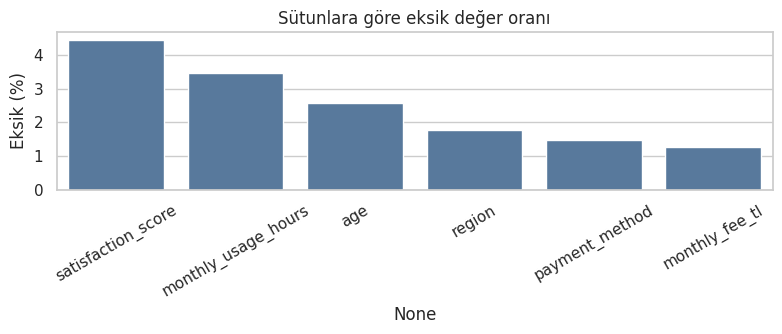

In [6]:
missing = pd.DataFrame({"eksik_adet": df_raw.isna().sum(), "eksik_yuzde": df_raw.isna().mean() * 100})
missing = missing[missing.eksik_adet > 0].sort_values("eksik_yuzde", ascending=False)
display(missing)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.barplot(x=missing.index, y=missing["eksik_yuzde"], color="#4c78a8", ax=ax)
ax.set_ylabel("Eksik (%)"); ax.set_title("Sütunlara göre eksik değer oranı"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

**Not:** Bu tabloda `monthly_fee_tl` yok; çünkü içinde `"free"`, `"?"` gibi *metin* var ve bunlar Pandas için "boş" değil, geçerli bir string. Bu, **eksik değerin her zaman NaN olarak gelmediğinin** klasik örneği. Şimdi bozuk ücret değerlerine bakalım.

In [7]:
fee_numeric = pd.to_numeric(df_raw["monthly_fee_tl"], errors="coerce")
text_fee = df_raw.loc[fee_numeric.isna() & df_raw["monthly_fee_tl"].notna(), "monthly_fee_tl"]
display(Markdown(f"Sayıya çevrilemeyen ücret değerleri (**{len(text_fee)}** adet): " + ", ".join(f"`{v}`" for v in text_fee)))
display(fee_numeric.describe().to_frame("sayıya çevrilebilen ücretler").T)
display(df_raw.loc[(fee_numeric <= 0) | (fee_numeric > 1000), ["customer_id", "plan", "discount_rate", "monthly_fee_tl"]])

Sayıya çevrilemeyen ücret değerleri (**7** adet): `399TL`, `free`, `error`, `?`, `—`, `unknown`, `four hundred`

,count,mean,std,min,25%,50%,75%,max
sayıya çevrilebilen ücretler,"1,790.000",356.287,259.923,-100.000,236.550,359.100,399.000,"9,999.000"


,customer_id,plan,discount_rate,monthly_fee_tl
387,CUST100387,Basic,0.100,9999.0
425,CUST100425,Basic,0.100,0.0
1323,CUST101323,Premium,0.050,-100.0
1804,CUST100425,Basic,0.100,0.0


## 2.6 Tekrarlayan kayıtlar — iki ayrı problem!
1. **Birebir aynı satır** (tüm sütunlar aynı).
2. **Aynı `customer_id`, farklı bilgiler** (çelişki). Bu çok daha sinsi: hangisi doğru?

In [8]:
exact = df_raw.duplicated(keep=False)
display(Markdown(f"Birebir tekrar eden satır (ilk kopya hariç): **{df_raw.duplicated().sum()}**"))
id_dups = df_raw[df_raw.duplicated(subset='customer_id', keep=False) & ~df_raw.duplicated(keep=False)]
display(Markdown(f"Birebir kopya olmayıp aynı `customer_id`'yi paylaşan satır: **{len(id_dups)}** ({id_dups.customer_id.nunique()} müşteri)"))
display(id_dups.sort_values("customer_id")[["customer_id", "monthly_usage_hours", "support_calls_6m", "monthly_fee_tl", "satisfaction_score"]].assign(satir_no=lambda d: d.index))

Birebir tekrar eden satır (ilk kopya hariç): **12**

Birebir kopya olmayıp aynı `customer_id`'yi paylaşan satır: **16** (8 müşteri)

,customer_id,monthly_usage_hours,support_calls_6m,monthly_fee_tl,satisfaction_score,satir_no
201,CUST100201,54.900,1,359.1,4.600,201
1818,CUST100201,62.900,2,359.1,4.600,1818
312,CUST100312,51.100,0,539.1,10.000,312
1815,CUST100312,60.100,1,539.1,10.000,1815
322,CUST100322,45.000,0,free,5.700,322
1814,CUST100322,55.000,1,509.15,5.700,1814
826,CUST100826,47.000,0,249.0,8.800,826
1813,CUST100826,57.000,1,249.0,8.800,1813
855,CUST100855,26.900,0,249.0,6.400,855
1812,CUST100855,38.900,1,249.0,6.400,1812


**Okuma:** Çelişkili çiftlerde fark genelde `monthly_usage_hours` (+birkaç saat) ve `support_calls_6m` (+1). Çelişen satırlar dosyanın **sonuna** eklenmiş (satır no ≥ 1812). Zaman damgamız olmadığı için hangisinin doğru olduğunu *kanıtlayamayız*; Notebook 03'te bunu bir **varsayım** olarak ele alacağız.

## 2.7 İş kurallarına göre geçerlilik kontrolü
Veri sözlüğündeki aralıkları (`config.RANGE_RULES`) ham veriye uyguluyoruz — **hiçbir şeyi silmeden sayıyoruz.**

In [9]:
rows = []
for col, (lo, hi) in C.RANGE_RULES.items():
    bad = df_raw[col].notna() & ~df_raw[col].between(lo, hi)
    rows.append({"sütun": col, "geçerli_aralık": f"[{lo}, {hi}]", "geçersiz_adet": int(bad.sum()),
                 "geçersiz_değerler": sorted(df_raw.loc[bad, col].unique().tolist())})
display(pd.DataFrame(rows))

,sütun,geçerli_aralık,geçersiz_adet,geçersiz_değerler
0,age,"[18, 100]",6,"[-3.0, 8.0, 12.0, 105.0, 130.0]"
1,tenure_months,"[1, 72]",0,[]
2,monthly_usage_hours,"[0, 100]",4,"[-5.0, -1.0, 145.0, 180.0]"
3,discount_rate,"[0.0, 0.2]",0,[]
4,satisfaction_score,"[1, 10]",2,"[0.0, 11.0]"


## 2.8 Alanlar arası tutarlılık: ücret nasıl oluşuyor?
Tek tek sütunlara bakmak yetmez; **sütunlar birbirini açıklayabilir.** `monthly_fee_tl` ile `plan` ve `discount_rate` arasında bir ilişki var mı?

In [10]:
plan_clean = df_raw["plan"].str.strip().str.title()
implied_list_price = (fee_numeric / (1 - df_raw["discount_rate"])).round(2)
display(pd.crosstab(plan_clean, implied_list_price).loc[:, lambda d: d.sum() > 3])

col_0,249.000,399.000,599.000
plan,,,
Basic,733,3,2
Premium,0,0,378
Standard,0,670,0


**Büyük keşif:** `ücret / (1 − indirim)` hesapladığımızda değerler neredeyse hep **249 (Basic), 399 (Standard), 599 (Premium)** çıkıyor. Yani:

$$\text{ücret} = \text{plan liste fiyatı} \times (1 - \text{indirim})$$

Bu kural iki işe yarayacak (Notebook 03): eksik/bozuk ücreti **tahmin etmek yerine kesin olarak geri hesaplamak** ve plan ile ücret *çeliştiğinde* hatalı alanı yakalamak. Yukarıdaki tabloda yalnızca en az 4 gözlemi olan fiyatları gösterdik; kuralı bozan nadir hücreleri hemen aşağıda ayrıca listeliyoruz.

In [11]:
cross = pd.DataFrame({"plan": plan_clean, "implied": implied_list_price})
price_to_plan = {v: k for k, v in C.PLAN_BASE_PRICE.items()}
cross["implied_plan"] = cross["implied"].map(price_to_plan)
conflict = cross[cross.implied_plan.notna() & (cross.implied_plan != cross.plan)]
display(Markdown(f"**Plan etiketi ile ücretin işaret ettiği plan çelişen satır sayısı: {len(conflict)}**"))
display(df_raw.loc[conflict.index, ["customer_id", "plan", "discount_rate", "monthly_fee_tl"]].assign(ucretin_isaret_ettigi_plan=conflict.implied_plan))

**Plan etiketi ile ücretin işaret ettiği plan çelişen satır sayısı: 5**

,customer_id,plan,discount_rate,monthly_fee_tl,ucretin_isaret_ettigi_plan
159,CUST100159,basic,0.000,599.0,Premium
758,CUST100758,basic,0.050,569.05,Premium
882,CUST100882,basic,0.000,399.0,Standard
905,CUST100905,basic,0.000,399.0,Standard
906,CUST100906,basic,0.000,399.0,Standard


## 2.9 Denetim özeti (veri kalitesi sorun listesi)
| # | Sorun | Nerede | Çözüm (Notebook 03) |
|---|---|---|---|
| 1 | Ücret metin içeriyor (`free`, `?`, `399TL` …) | `monthly_fee_tl` | Sayıya çevir; formülle doğrula/geri kazan |
| 2 | Aralık dışı değerler | `age`, `monthly_usage_hours`, `satisfaction_score`, ücret | NaN yap, eğitimde imputer doldursun |
| 3 | Büyük/küçük harf tutarsızlığı | `region`, `plan`, `contract_type`, `payment_method` | Standartlaştır |
| 4 | Plan ↔ ücret çelişkisi | `plan` | Ücret/indirimden plan türet |
| 5 | Birebir tekrar satırlar | tüm satır | Sil |
| 6 | Aynı ID, farklı bilgi | `customer_id` | İlk kaydı tut (varsayım) + denetim dosyası |
| 7 | Gerçek eksik değerler | 5 sütun | **Silme, doldurma Pipeline içinde** (leakage olmasın) |